Original Dataset:
    Hours_Studied  Marks
0               2     35
1               3     38
2               4     42
3               5     45
4               6     49
5               7     52
6               8     56
7               9     60
8              10     63
9              11     67
10             12     70
11             13     74
12             14     78
13             15     81
14             16     85

Actual Marks:
[67 74 35]

Predicted Marks:
[66.81 74.01 34.42]

Linear Regression Results:
Intercept: 27.225997629395494
Coefficient: 3.598972738048202

Regression Equation:
Marks = 27.23 + 3.60 * Hours

Model Evaluation:
Mean Squared Error: 0.1221127738159296
R2 Score: 0.9995763242234605

New Student Marks Prediction:
 Hours_Studied  Predicted_Marks
             5            45.22
             8            56.02
            10            63.22
            12            70.41
            15            81.21
            18            92.01


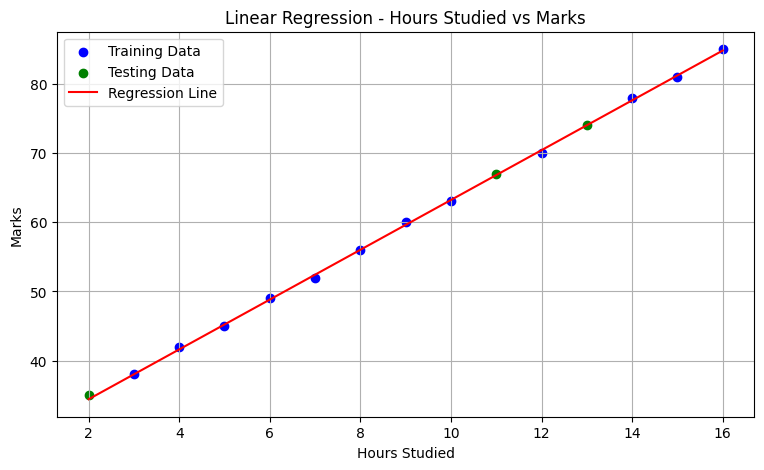

In [1]:

# Problem 4: Simple Linear Regression
# Hours Studied vs Marks

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 2. Create dataset
data = {
    'Hours_Studied': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16],
    'Marks': [35, 38, 42, 45, 49, 52, 56, 60, 63, 67, 70, 74, 78, 81, 85]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# 3. Separate input and output
X = df[['Hours_Studied']]
y = df['Marks']

# 4. Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Create Linear Regression model
model = LinearRegression()

# 6. Train the model
model.fit(X_train, y_train)

# 7. Predict test data
y_pred = model.predict(X_test)

print("\nActual Marks:")
print(y_test.values)

print("\nPredicted Marks:")
print(np.round(y_pred, 2))

# 8. Display model parameters
print("\nLinear Regression Results:")
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

print("\nRegression Equation:")
print(f"Marks = {model.intercept_:.2f} + {model.coef_[0]:.2f} * Hours")

# 9. Evaluate model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

# 10. Predict marks for new study hours
new_hours = pd.DataFrame({
    'Hours_Studied': [5, 8, 10, 12, 15, 18]
})

predicted_marks = model.predict(new_hours)

prediction_df = pd.DataFrame({
    'Hours_Studied': new_hours['Hours_Studied'],
    'Predicted_Marks': np.round(predicted_marks, 2)
})

print("\nNew Student Marks Prediction:")
print(prediction_df.to_string(index=False))

# 11. Visualize Linear Regression
plt.figure(figsize=(9, 5))

plt.scatter(
    X_train, y_train,
    color='blue',
    label='Training Data'
)

plt.scatter(
    X_test, y_test,
    color='green',
    label='Testing Data'
)

plt.plot(
    X,
    model.predict(X),
    color='red',
    label='Regression Line'
)

plt.xlabel('Hours Studied')
plt.ylabel('Marks')
plt.title('Linear Regression - Hours Studied vs Marks')
plt.legend()
plt.grid(True)
plt.show()
